# E-Commerce Customer Segmentation

## Introduction
Customer segmentation is the process of dividing customers
into groups based on their purchasing behaviour.

This project uses transaction data from an online retailer
to identify different customer segments using RFM analysis.

## Objectives
- Perform exploratory data analysis.
- Calculate Recency, Frequency and Monetary values.
- Apply K-Means and DBSCAN clustering.
- Reduce dimensions using PCA.
- Visualize customer segments using t-SNE.
- Derive actionable customer personas.
- Recommend targeted marketing strategies.

## Algorithms
1. K-Means Clustering
2. DBSCAN Clustering
3. Principal Component Analysis (PCA)
4. t-SNE

In [63]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Dimensionality reduction
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Clustering algorithms
from sklearn.cluster import KMeans, DBSCAN

# Nearest neighbors
from sklearn.neighbors import NearestNeighbors

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Dataset Loading

The Online Retail dataset contains transaction records
from an online retail business.

It includes invoice details, product information,
quantities, prices, transaction dates and customer IDs.

This dataset is used to understand customer purchasing
behaviour and identify meaningful customer segments.

In [64]:
# Load dataset
df = pd.read_excel("/content/Online Retail.xlsx")

# Display first five rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [65]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display the first five records
display(df.head())

Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [83]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display dataset information
df.info()

# Statistical summary
df.describe()

Dataset Shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


## 2. Data Cleaning and Preprocessing

Missing values and duplicate records can affect the
reliability of customer segmentation.

We identify missing values and remove records without
CustomerID because customer identification is essential
for calculating RFM metrics.

Missing product descriptions are retained because they
are not required for RFM analysis.

In [84]:
# Check missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_values)

,Missing Values,Missing Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


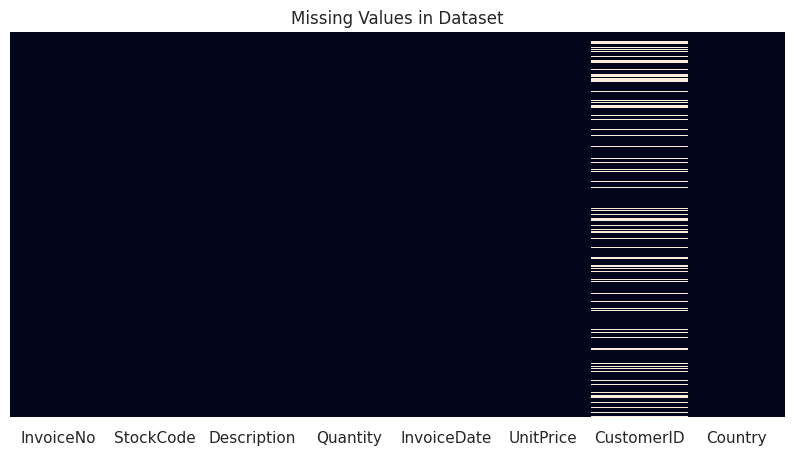

In [85]:
# Visualize missing values
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values in Dataset")
plt.show()

In [86]:
# Remove rows where CustomerID is missing
df = df.dropna(subset=["CustomerID"])

print("Shape after handling missing CustomerID:", df.shape)

Shape after handling missing CustomerID: (406829, 8)


In [89]:
# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Convert columns to appropriate data types
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate total transaction amount
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned Dataset Shape:", df.shape)

df.head()

Duplicate Records: 0
Cleaned Dataset Shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [98]:
# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

# Calculate total transaction amount
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned Dataset Shape:", df.shape)

df.head()

Cleaned Dataset Shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 3. RFM Feature Engineering

RFM analysis is a customer segmentation technique that evaluates
customer purchasing behaviour using three important metrics:

1. Recency: Number of days since the customer's last purchase.
2. Frequency: Number of unique invoices generated by the customer.
3. Monetary: Total amount spent by the customer.

These three metrics help identify purchasing patterns and
form the basis for customer segmentation using machine learning.

In [99]:
# Set reference date as one day after the latest transaction
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Group transactions by CustomerID and calculate RFM metrics
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})

# Rename columns
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Display RFM dataset information
print("RFM Dataset Shape:", rfm.shape)

display(rfm.head())

RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


### RFM Feature Distribution

The distribution of Recency, Frequency and Monetary values
is visualized to understand customer purchasing behaviour.

This helps identify skewness and differences in the
numerical ranges of the three features.

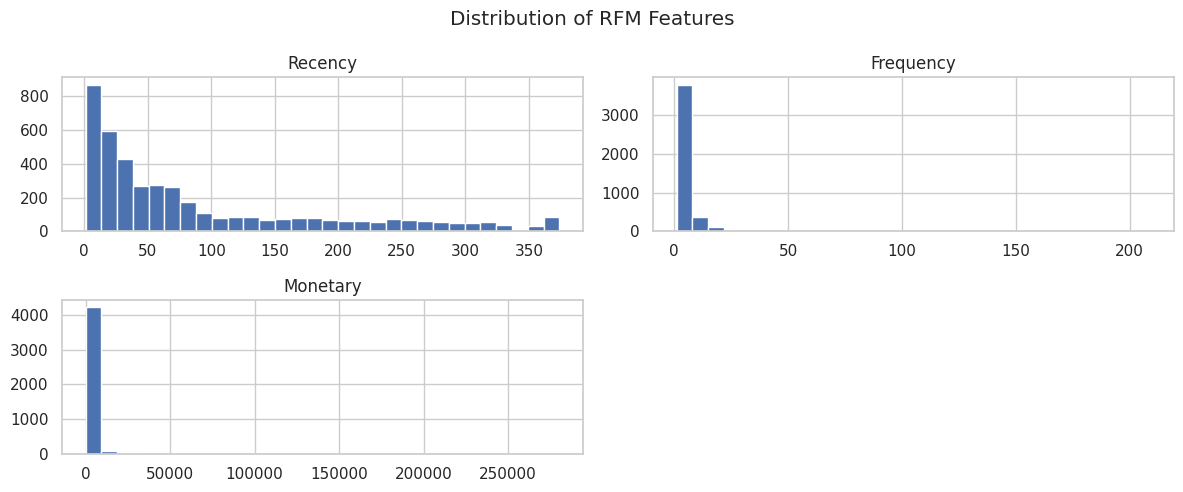

In [100]:
# Visualize the distribution of RFM features
rfm[["Recency", "Frequency", "Monetary"]].hist(
    figsize=(12, 5),
    bins=30
)

plt.suptitle("Distribution of RFM Features")
plt.tight_layout()
plt.show()

### Data Transformation and Feature Scaling

RFM features have different numerical ranges and distributions.

Log transformation is applied to reduce the effect of
skewness in the data.

StandardScaler is then used to standardize all three features
so that they contribute comparably to distance-based
clustering algorithms.

In [101]:
# Apply log transformation to reduce skewness
rfm_log = np.log1p(
    rfm[["Recency", "Frequency", "Monetary"]]
)

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the transformed RFM features
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

# Display the scaled dataset
print("Feature Scaling Completed!")

display(rfm_scaled.head())

Feature Scaling Completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


In [102]:
# Lists to store evaluation values
inertia_values = []
silhouette_values = []

# Test different numbers of clusters
k_values = range(2, 11)

for k in k_values:

    # Initialize K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit model and obtain cluster labels
    labels = model.fit_predict(rfm_scaled)

    # Store inertia value
    inertia_values.append(model.inertia_)

    # Store silhouette score
    silhouette_values.append(
        silhouette_score(rfm_scaled, labels)
    )

print("K-Means experiments completed!")

K-Means experiments completed!


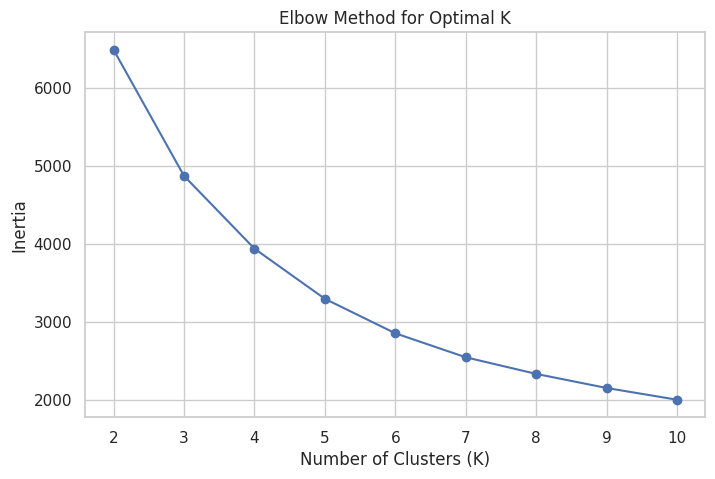

In [103]:
# Plot inertia values for different K
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.grid(True)
plt.show()

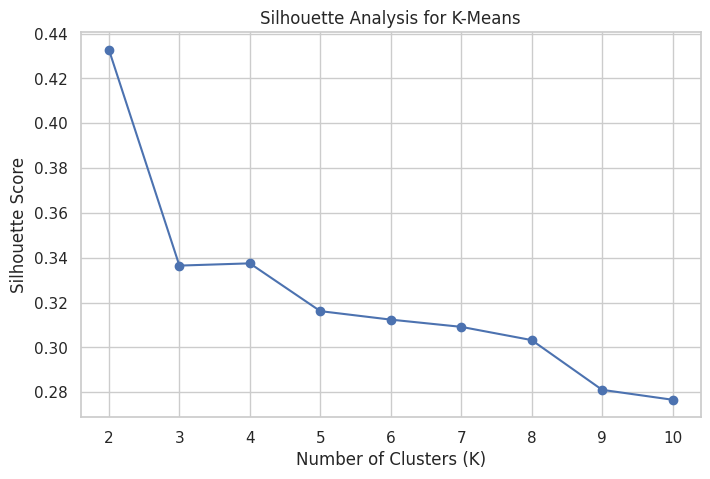

In [104]:
# Plot silhouette scores for different K
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for K-Means")

plt.grid(True)
plt.show()

### K-Means Model Training

After examining the Elbow Method and Silhouette Score,
a suitable number of clusters is selected.

The final K-Means model is trained using the scaled RFM
features, and each customer is assigned a cluster label.

In [105]:
# Select K based on the previous evaluation graphs
optimal_k = 4  # Change this if your graphs support another value

# Initialize final K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Train the model and predict customer clusters
kmeans_labels = kmeans.fit_predict(rfm_scaled)

# Store cluster assignments
rfm["KMeans_Cluster"] = kmeans_labels

print("K-Means Model Training Completed!")

display(rfm.head())

K-Means Model Training Completed!


,Recency,Frequency,Monetary,KMeans_Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,3
12349,19,1,1757.55,2
12350,310,1,334.40,1


### Customer Distribution Across Clusters

The number of customers assigned to each K-Means cluster
is calculated and visualized.

This helps understand the size of each identified
customer segment.

,count
KMeans_Cluster,
0,713
1,1622
2,837
3,1166


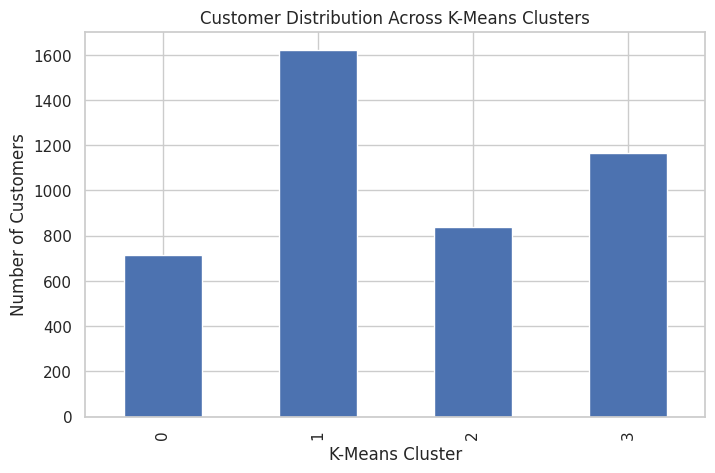

In [106]:
# Count customers in each cluster
cluster_counts = (
    rfm["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

display(cluster_counts)

# Visualize customer distribution
plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.xlabel("K-Means Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution Across K-Means Clusters")

plt.show()

## Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is a dimensionality
reduction technique used to convert the original RFM
features into a smaller number of components.

In this project, three RFM features are reduced to
two principal components.

This allows customer clusters to be visualized in
a two-dimensional space while retaining as much
of the original data variance as possible.

In [107]:
# Initialize PCA with two components
pca = PCA(n_components=2)

# Transform scaled RFM features into two dimensions
rfm_pca = pca.fit_transform(rfm_scaled)

# Display explained variance
print("Explained Variance Ratio:", pca.explained_variance_ratio_)

print(
    "Total Variance Explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Explained Variance Ratio: [0.75078634 0.18786648]
Total Variance Explained: 93.87 %


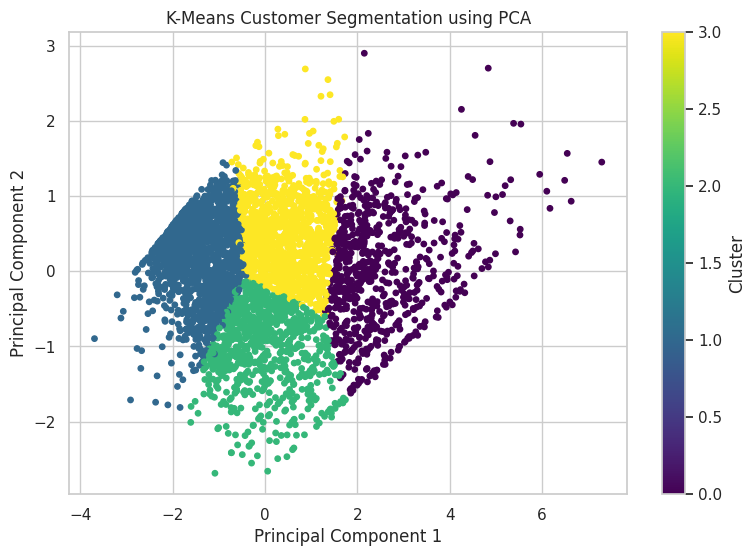

In [108]:
# Plot K-Means clusters using PCA components
plt.figure(figsize=(9, 6))

plt.scatter(
    rfm_pca[:, 0],
    rfm_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Segmentation using PCA")

plt.colorbar(label="Cluster")

plt.show()

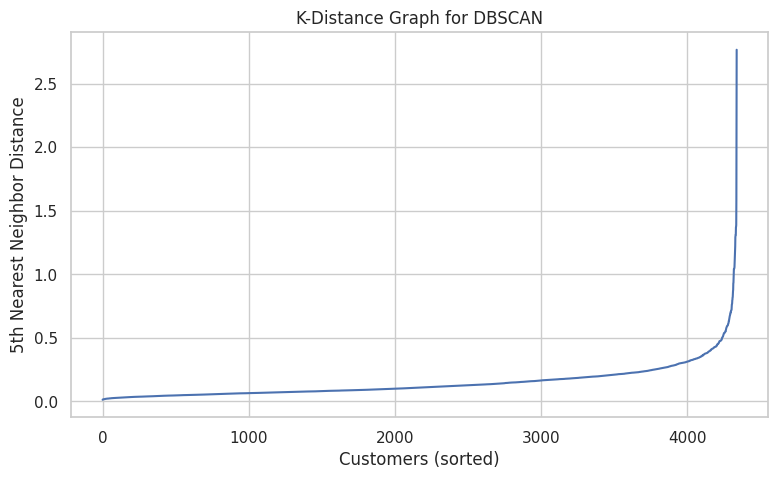

In [109]:
# Initialize nearest neighbors with 5 neighbors
neighbors = NearestNeighbors(n_neighbors=5)

# Fit the model on scaled RFM data
neighbors.fit(rfm_scaled)

# Calculate distances and indices of nearest neighbors
distances, indices = neighbors.kneighbors(rfm_scaled)

# Sort the distance to the fifth nearest neighbor
k_distances = np.sort(distances[:, 4])

# Plot K-distance graph
plt.figure(figsize=(9, 5))

plt.plot(k_distances)

plt.xlabel("Customers (sorted)")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Graph for DBSCAN")

plt.grid(True)
plt.show()

### DBSCAN Parameter Tuning

Different eps values are tested while keeping min_samples
fixed at 5.

The number of clusters and noise points are examined
to understand how parameter changes affect the results.

A suitable combination is selected using the K-distance
graph and the resulting cluster distribution.

In [110]:
# Test different eps values
eps_values = [0.3, 0.5, 0.7, 0.9, 1.1]

for eps in eps_values:

    # Initialize DBSCAN
    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    # Fit model and predict cluster labels
    labels = model.fit_predict(rfm_scaled)

    # Count clusters, excluding noise label -1
    cluster_count = len(set(labels) - {-1})

    # Count noise points
    noise_count = np.sum(labels == -1)

    # Calculate noise percentage
    noise_percentage_temp = (
        noise_count / len(labels)
    ) * 100

    print(
        f"eps={eps} | "
        f"Clusters={cluster_count} | "
        f"Noise={noise_count} | "
        f"Noise Percentage={noise_percentage_temp:.2f}%"
    )

eps=0.3 | Clusters=8 | Noise=247 | Noise Percentage=5.69%
eps=0.5 | Clusters=2 | Noise=62 | Noise Percentage=1.43%
eps=0.7 | Clusters=2 | Noise=26 | Noise Percentage=0.60%
eps=0.9 | Clusters=1 | Noise=13 | Noise Percentage=0.30%
eps=1.1 | Clusters=1 | Noise=7 | Noise Percentage=0.16%


### DBSCAN Model Training

After examining the K-distance graph and parameter
experiments, the final DBSCAN parameters are selected.

The model identifies dense customer groups and labels
customers that do not belong to any cluster as noise (-1).

In [111]:
# Select parameters based on previous experiments
selected_eps = 0.5       # Replace with your selected value
selected_min_samples = 5

# Initialize final DBSCAN model
dbscan = DBSCAN(
    eps=selected_eps,
    min_samples=selected_min_samples
)

# Fit DBSCAN and predict cluster labels
dbscan_labels = dbscan.fit_predict(rfm_scaled)

# Store DBSCAN cluster assignments
rfm["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN Model Training Completed!")

display(rfm.head())

DBSCAN Model Training Completed!


,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster
CustomerID,,,,,
12346,326,1,77183.60,3,-1
12347,2,7,4310.00,0,0
12348,75,4,1797.24,3,0
12349,19,1,1757.55,2,1
12350,310,1,334.40,1,1


### DBSCAN Cluster and Noise Analysis

The number of customers in each DBSCAN cluster is calculated.

Noise points are represented by the label -1.
These points are not assigned to any regular cluster.

The noise percentage helps measure the proportion
of customers that DBSCAN could not group into dense regions.

In [112]:
# Count customers in each DBSCAN cluster
dbscan_counts = (
    rfm["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

display(dbscan_counts)

# Count clusters, excluding noise
dbscan_cluster_count = len(set(dbscan_labels) - {-1})

# Count noise points
noise_count = np.sum(dbscan_labels == -1)

# Calculate noise percentage
noise_percentage = (
    noise_count / len(dbscan_labels)
) * 100

print("Number of DBSCAN Clusters:", dbscan_cluster_count)
print("Number of Noise Points:", noise_count)
print("Noise Percentage:", round(noise_percentage, 2), "%")

,count
DBSCAN_Cluster,
-1,62
0,2791
1,1485


Number of DBSCAN Clusters: 2
Number of Noise Points: 62
Noise Percentage: 1.43 %


### PCA Visualization of DBSCAN Clusters

The DBSCAN cluster assignments are visualized using
the two PCA components.

Different colours represent the identified clusters,
while -1 represents noise points.

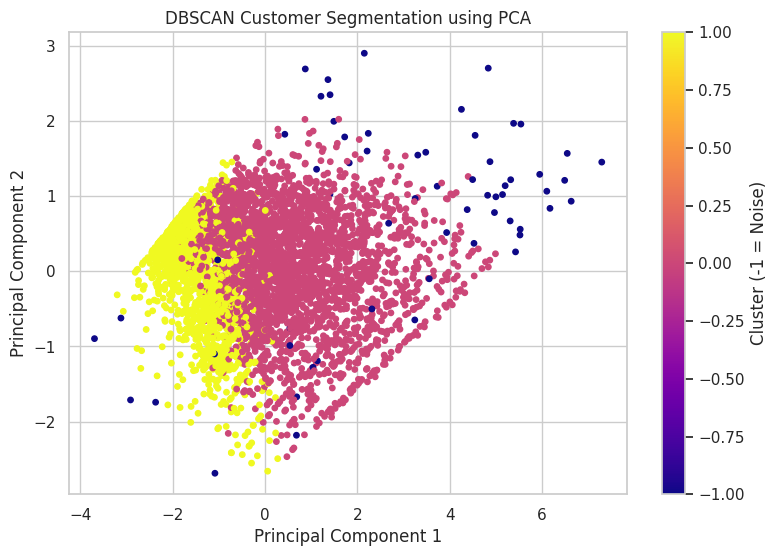

In [113]:
# Plot DBSCAN clusters using PCA
plt.figure(figsize=(9, 6))

plt.scatter(
    rfm_pca[:, 0],
    rfm_pca[:, 1],
    c=dbscan_labels,
    cmap="plasma",
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Customer Segmentation using PCA")

plt.colorbar(label="Cluster (-1 = Noise)")

plt.show()

## t-SNE Visualization

t-SNE (t-Distributed Stochastic Neighbor Embedding)
is a dimensionality reduction technique used to visualize
similarities between data points.

It transforms the scaled RFM features into a two-dimensional
representation while attempting to preserve local
neighborhood relationships.

This helps visualize the customer groups identified
by K-Means and DBSCAN.

In [114]:
# Select a valid perplexity based on the number of customers
perplexity_value = min(30, len(rfm_scaled) - 1)

# Initialize t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=perplexity_value,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

# Transform scaled RFM features into two dimensions
rfm_tsne = tsne.fit_transform(rfm_scaled)

print("t-SNE Visualization Completed!")

t-SNE Visualization Completed!


### K-Means Visualization using t-SNE

The t-SNE representation is plotted using K-Means
cluster labels.

This visualization helps examine local patterns
and similarities among customers in different segments.

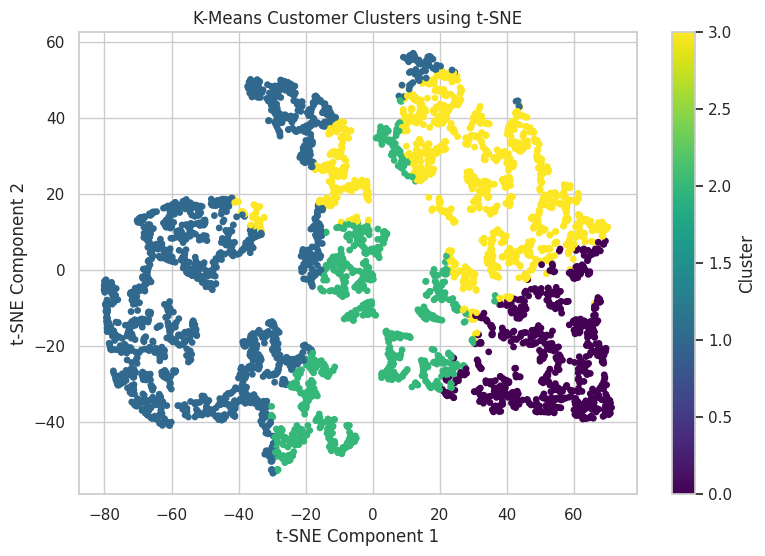

In [115]:
# Plot K-Means clusters using t-SNE
plt.figure(figsize=(9, 6))

plt.scatter(
    rfm_tsne[:, 0],
    rfm_tsne[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=15
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Customer Clusters using t-SNE")

plt.colorbar(label="Cluster")

plt.show()

### DBSCAN Visualization using t-SNE

The t-SNE representation is also plotted using DBSCAN
cluster labels.

Noise points are represented by the label -1.

This provides another visual perspective on the dense
customer groups identified by DBSCAN.

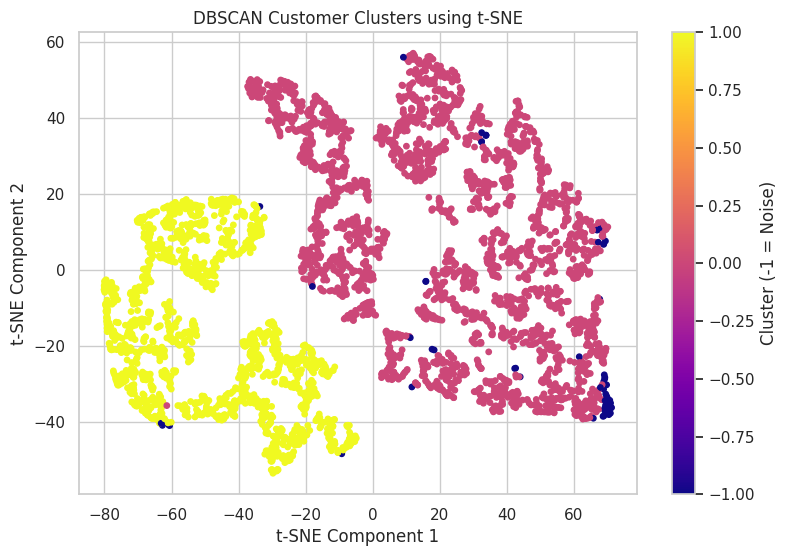

In [116]:
# Plot DBSCAN clusters using t-SNE
plt.figure(figsize=(9, 6))

plt.scatter(
    rfm_tsne[:, 0],
    rfm_tsne[:, 1],
    c=dbscan_labels,
    cmap="plasma",
    s=15
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("DBSCAN Customer Clusters using t-SNE")

plt.colorbar(label="Cluster (-1 = Noise)")

plt.show()

## 9. Model Evaluation

Clustering performance is evaluated using three metrics:

1. Silhouette Score:
   Measures how well-separated the clusters are.
   Higher values generally indicate better clustering.

These metrics help assess the quality of the clustering results.

In [118]:
# Import clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [119]:
# Evaluate K-Means clustering
print("K-Means Model Evaluation")

# Calculate Silhouette Score
kmeans_silhouette = silhouette_score(
    rfm_scaled,
    kmeans_labels
)

# Display evaluation results
print("Silhouette Score:", round(kmeans_silhouette, 4))

K-Means Model Evaluation
Silhouette Score: 0.3375


In [120]:
# Identify customers assigned to regular DBSCAN clusters
non_noise_mask = dbscan_labels != -1

# Select non-noise customer data
dbscan_data = rfm_scaled.loc[non_noise_mask]

# Select corresponding cluster labels
dbscan_valid_labels = dbscan_labels[non_noise_mask]

# Count DBSCAN clusters excluding noise
valid_cluster_count = len(set(dbscan_valid_labels))

print("DBSCAN Model Evaluation")

# Metrics require at least two clusters and more observations than clusters
if valid_cluster_count >= 2 and len(dbscan_valid_labels) > valid_cluster_count:

    # Calculate Silhouette Score
    dbscan_silhouette = silhouette_score(
        dbscan_data,
        dbscan_valid_labels
    )

    # Display results
    print("Silhouette Score:", round(dbscan_silhouette, 4))

else:
    print("DBSCAN does not have enough valid clusters for evaluation.")

# Display noise percentage
print("Noise Percentage:", round(noise_percentage, 2), "%")

DBSCAN Model Evaluation
Silhouette Score: 0.293
Noise Percentage: 1.43 %


In [121]:
# Store K-Means evaluation results
comparison_results = {
    "Model": ["K-Means", "DBSCAN"],
    "Silhouette Score": [
        kmeans_silhouette,
        dbscan_silhouette if valid_cluster_count >= 2 else np.nan
    ]
}

# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,Silhouette Score
0,K-Means,0.3375
1,DBSCAN,0.2930


In [122]:
# Calculate average RFM values for each K-Means cluster
kmeans_summary = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

# Display cluster characteristics
display(kmeans_summary)

,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,12.17,13.75,8088.02
1,181.51,1.32,341.00
2,17.70,2.19,557.32
3,71.64,4.08,1801.78


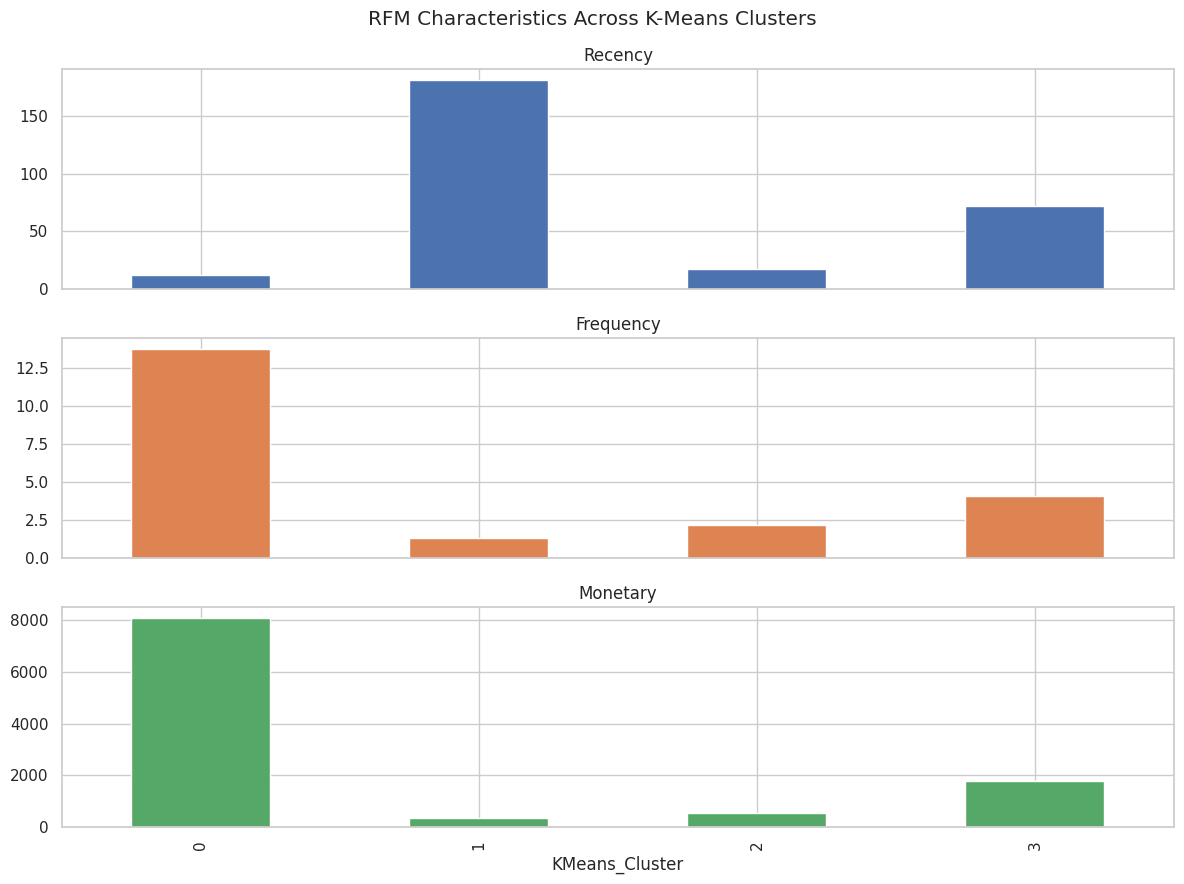

In [123]:
# Visualize average RFM metrics across clusters
kmeans_summary.plot(
    kind="bar",
    subplots=True,
    figsize=(12, 9),
    layout=(3, 1),
    legend=False
)

plt.suptitle("RFM Characteristics Across K-Means Clusters")
plt.tight_layout()
plt.show()

In [124]:
# Assign personas based on the actual RFM cluster analysis
# Change these labels after inspecting kmeans_summary

persona_mapping = {
    0: "Champions",
    1: "Hibernating Customers",
    2: "Potential Customers",
    3: "At-Risk Customers"
}

# Add persona labels to customer records
rfm["Customer_Persona"] = (
    rfm["KMeans_Cluster"].map(persona_mapping)
)

# Display customer records with assigned personas
display(rfm.head(10))

,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster,Customer_Persona
CustomerID,,,,,,
12346,326,1,77183.60,3,-1,At-Risk Customers
12347,2,7,4310.00,0,0,Champions
12348,75,4,1797.24,3,0,At-Risk Customers
12349,19,1,1757.55,2,1,Potential Customers
12350,310,1,334.40,1,1,Hibernating Customers
12352,36,8,2506.04,3,0,At-Risk Customers
12353,204,1,89.00,1,1,Hibernating Customers
12354,232,1,1079.40,1,1,Hibernating Customers
12355,214,1,459.40,1,1,Hibernating Customers


In [127]:
# Display the final customer segmentation results
display(rfm.head(10))

# Display final dataset dimensions
print("Final Dataset Shape:", rfm.shape)

# Export customer-level segmentation results
rfm.to_csv(
    "Ecommerce_Customer_Segmentation_Results.csv"
)

# Export K-Means customer persona summary
kmeans_summary.to_csv(
    "Customer_Persona_Summary.csv"
)


# Export model comparison results
comparison_df.to_csv(
    "Model_Comparison.csv",
    index=False
)

print("All result files exported successfully!")

,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster,Customer_Persona
CustomerID,,,,,,
12346,326,1,77183.60,3,-1,At-Risk Customers
12347,2,7,4310.00,0,0,Champions
12348,75,4,1797.24,3,0,At-Risk Customers
12349,19,1,1757.55,2,1,Potential Customers
12350,310,1,334.40,1,1,Hibernating Customers
12352,36,8,2506.04,3,0,At-Risk Customers
12353,204,1,89.00,1,1,Hibernating Customers
12354,232,1,1079.40,1,1,Hibernating Customers
12355,214,1,459.40,1,1,Hibernating Customers


Final Dataset Shape: (4338, 6)
All result files exported successfully!


In [129]:
# Download generated result files
from google.colab import files

files.download("Ecommerce_Customer_Segmentation_Results.csv")

files.download("Customer_Persona_Summary.csv")

files.download("Model_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

This project demonstrates customer segmentation using
RFM analysis and unsupervised machine learning techniques.

The Recency, Frequency and Monetary metrics are calculated
to understand individual customer purchasing behaviour.

K-Means and DBSCAN are applied to identify meaningful
customer groups based on their transaction patterns.

PCA and t-SNE are used to visualize the identified
customer segments in two-dimensional space.

The clustering results are evaluated using Silhouette Score
Finally, the customer groups are interpreted into
meaningful personas and targeted marketing strategies
are recommended.

Overall, the project demonstrates how transaction data
can be transformed into actionable business insights
using unsupervised machine learning.